# Türkiye Elektrik Üretimi — Veri Hazırlama ve Kontrol

Bu notebook, proje klasöründeki iki ham OWID CSV dosyasını kullanır. Türkiye'nin 1965–2025 ayrıntılı serisi özel Türkiye CSV'sinden; karşılaştırma ülkeleri ve Dünya serisi dünya CSV'sinden alınır.

Eksik gözlemler eksik olarak korunur; sıfırla doldurulmaz. Dünya CSV'sinde toplam elektrik üretimi sütunu bulunmadığından, diğer ülkeler için toplam üretim içindeki pay hesaplanmaz; karşılaştırma analizinde beş seçilmiş kaynak paydası (Kömür + Gaz + Hidro + Rüzgâr + Güneş) açıkça belirtilerek kullanılır. Web grafiğindeki kaynak verileri için JSON çıktıları proje klasörüne kaydedilir.

In [1]:
from pathlib import Path
import json
import pandas as pd

# Notebook'u proje kökünden veya notebooks klasöründen çalıştırılabilir tut.
def find_project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        has_world_csv = (candidate / "data" / "raw" / "ham_dunya_enerji.csv").is_file()
        has_turkey_csv = (candidate / "data" / "raw" / "turkiye-elektrik-kaynaklari.csv").is_file()
        if has_world_csv and has_turkey_csv:
            return candidate
    raise FileNotFoundError(
        "Proje kökü bulunamadı. Notebook'u, data/raw klasörünü içeren proje içinde açın."
    )

PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
WORLD_PATH = RAW_DIR / "ham_dunya_enerji.csv"
TURKEY_PATH = RAW_DIR / "turkiye-elektrik-kaynaklari.csv"

world_raw = pd.read_csv(WORLD_PATH)
turkey_raw = pd.read_csv(TURKEY_PATH)

print(f"Proje klasörü: {PROJECT_ROOT}")
print(f"Dünya CSV: {world_raw.shape[0]:,} satır, {world_raw.shape[1]} sütun")
print(f"Türkiye CSV: {turkey_raw.shape[0]:,} satır, {turkey_raw.shape[1]} sütun")
print("Dünya CSV sütunları:", ", ".join(world_raw.columns))
print("Türkiye CSV sütunları:", ", ".join(turkey_raw.columns))

Proje klasörü: C:\Users\Admin\Desktop\Yeni klasör
Dünya CSV: 10,582 satır, 12 sütun
Türkiye CSV: 61 satır, 11 sütun
Dünya CSV sütunları: Entity, Code, Year, Other renewables, Bioenergy, Solar, Wind, Hydropower, Nuclear, Gas, Oil, Coal
Türkiye CSV sütunları: Entity, Code, Year, Total electricity generation (TWh), Electricity from coal (TWh), Electricity from gas (TWh), Electricity from hydro (TWh), Electricity from wind (TWh), Electricity from solar (TWh), Electricity from other renewables (TWh), Electricity from bioenergy (TWh)


## Seçilen veri kapsamı

Web hikâyesinde ve küresel karşılaştırmada kullanılan 17 seri (16 ülke ve Dünya ortalaması): Brezilya, Çin, Danimarka, Fransa, Almanya, Yunanistan, Hindistan, İtalya, Japonya, Hollanda, Polonya, Portekiz, İspanya, Türkiye, Birleşik Krallık, ABD ve Dünya. Her seri 1965–2025 aralığına sınırlandırılır (61 yıl). Toplam beklenen kayıt sayısı ülke ve yıl listesinden dinamik olarak hesaplanır (`len(ENTITIES) * len(YEARS)` = 17 × 61 = 1.037 kayıt). Türkiye değerleri ayrıntılı Türkiye dosyasından alınır; diğer seriler dünya dosyasından gelir. Dünya dosyasındaki Code değeri olan OWID_WRL nedeniyle Dünya kaydı ayrıca ikinci kez eklenmez.

In [2]:
YEARS = range(1965, 2026)
ENTITIES = [
    "Brazil", "China", "Denmark", "France", "Germany", "Greece",
    "India", "Italy", "Japan", "Netherlands", "Poland", "Portugal",
    "Spain", "Turkey", "United Kingdom", "United States", "World",
]

# Kaynak dosyalarındaki sütun adlarını web sitesinin beklediği JSON alanlarına eşleştir.
WORLD_COLUMNS = {
    "Coal": "Coal",
    "Gas": "Gas",
    "Hydropower": "Hydropower",
    "Wind": "Wind",
    "Solar": "Solar",
    "OtherRenewables": "Other renewables",
    "Bioenergy": "Bioenergy",
    "Nuclear": "Nuclear",
}
TURKEY_COLUMNS = {
    "TotalElectricity": "Total electricity generation (TWh)",
    "Coal": "Electricity from coal (TWh)",
    "Gas": "Electricity from gas (TWh)",
    "Hydropower": "Electricity from hydro (TWh)",
    "Wind": "Electricity from wind (TWh)",
    "Solar": "Electricity from solar (TWh)",
    "OtherRenewables": "Electricity from other renewables (TWh)",
    "Bioenergy": "Electricity from bioenergy (TWh)",
}

world_selected = world_raw[
    world_raw["Entity"].isin(ENTITIES) & world_raw["Year"].between(1965, 2025)
].copy()
turkey_selected = turkey_raw[turkey_raw["Year"].between(1965, 2025)].copy()

# Yalnızca seçili aralıktaki kayıtları denetle; bir ülke-yıl için iki kayıt varsa sessizce seçme.
if world_selected.duplicated(["Entity", "Year"]).any():
    duplicates = world_selected.loc[
        world_selected.duplicated(["Entity", "Year"], keep=False), ["Entity", "Year"]
    ]
    raise ValueError(f"Dünya CSV'sinde yinelenen ülke-yıl kayıtları var:\n{duplicates}")
if turkey_selected.duplicated(["Entity", "Year"]).any():
    raise ValueError("Türkiye CSV'sinde yinelenen yıl kayıtları var.")

world_lookup = world_selected.set_index(["Entity", "Year"]).to_dict(orient="index")
turkey_lookup = turkey_selected.set_index("Year").to_dict(orient="index")

# Dünya serisinin nükleer alanı Türkiye CSV'sinde bulunmadığı için yalnız bu alan dünya dosyasından alınır.
turkey_world_rows = world_selected[world_selected["Entity"].eq("Turkey")]
nuclear_by_year = turkey_world_rows.set_index("Year")["Nuclear"].to_dict()

def as_number(value):
    """Eksik değeri None (JSON null) olarak koru; mevcut sayıları iki haneye yuvarla."""
    if value is None or pd.isna(value):
        return None
    return round(float(value), 2)

records = []
missing_source_rows = []
for entity in ENTITIES:
    for year in YEARS:
        if entity == "Turkey":
            row = turkey_lookup.get(year)
            if row is None:
                missing_source_rows.append((entity, year))
                continue
            record = {
                "Entity": "Turkey",
                "Code": row.get("Code"),
                "Year": int(year),
                **{key: as_number(row.get(column)) for key, column in TURKEY_COLUMNS.items()},
                "Nuclear": as_number(nuclear_by_year.get(year)),
            }
        else:
            row = world_lookup.get((entity, year))
            if row is None:
                missing_source_rows.append((entity, year))
                continue
            record = {
                "Entity": entity,
                "Code": row.get("Code"),
                "Year": int(year),
                # Dünya CSV'sinde toplam üretim sütunu yok; bu alan bilinçli olarak null kalır.
                "TotalElectricity": None,
                **{key: as_number(row.get(column)) for key, column in WORLD_COLUMNS.items()},
            }
        records.append(record)

if missing_source_rows:
    raise ValueError(f"Kaynak CSV'de beklenen seri/yıl kayıtları eksik: {missing_source_rows[:10]}")

processed = pd.DataFrame(records).sort_values(["Entity", "Year"]).reset_index(drop=True)
expected_rows = len(ENTITIES) * len(YEARS)
assert len(processed) == expected_rows, f"Beklenen {expected_rows} kayıt, üretilen {len(processed)}"
assert not processed.duplicated(["Entity", "Year"]).any(), "Çıktıda yinelenen ülke-yıl var."

print(f"Hazırlanan kayıt sayısı: {len(processed)} (Beklenen: {expected_rows})")
print(f"Seriler ({processed['Entity'].nunique()}): {', '.join(sorted(processed['Entity'].unique()))}")
print(f"Yıllar: {processed['Year'].min()}–{processed['Year'].max()} ({len(YEARS)} yıl)")
processed.head()

Hazırlanan kayıt sayısı: 1037 (Beklenen: 1037)
Seriler (17): Brazil, China, Denmark, France, Germany, Greece, India, Italy, Japan, Netherlands, Poland, Portugal, Spain, Turkey, United Kingdom, United States, World
Yıllar: 1965–2025 (61 yıl)


,Entity,Code,Year,TotalElectricity,Coal,Gas,Hydropower,Wind,Solar,OtherRenewables,Bioenergy,Nuclear
0,Brazil,BRA,1965,NaN,NaN,NaN,25.52,NaN,NaN,NaN,0.0,0.0
1,Brazil,BRA,1966,NaN,NaN,NaN,27.91,NaN,NaN,NaN,0.0,0.0
2,Brazil,BRA,1967,NaN,NaN,NaN,29.19,NaN,NaN,NaN,0.0,0.0
3,Brazil,BRA,1968,NaN,NaN,NaN,30.55,NaN,NaN,NaN,0.0,0.0
4,Brazil,BRA,1969,NaN,NaN,NaN,32.69,NaN,NaN,NaN,0.0,0.0


## Eksik değer denetimi

Eksik değerleri sıfırla doldurmak raporlanmamış veriyi gerçek sıfır üretim gibi gösterebilir. Bu nedenle JSON'da bilinmeyen değerler null olarak korunur. Dünya kaynak CSV'si toplam elektrik üretimini içermediği için diğer ülkelerde TotalElectricity alanı null kalır. Türkiye'nin toplam üretim serisi ayrı kaynak dosyasından gelir.

In [3]:
value_columns = [
    "TotalElectricity", "Coal", "Gas", "Hydropower", "Wind", "Solar",
    "OtherRenewables", "Bioenergy", "Nuclear",
]
missing_summary = processed.groupby("Entity")[value_columns].apply(lambda group: group.isna().sum())
missing_summary

,TotalElectricity,Coal,Gas,Hydropower,Wind,Solar,OtherRenewables,Bioenergy,Nuclear
Entity,,,,,,,,,
Brazil,61,20,20,0,20,25,5,0,0
China,61,20,20,0,6,6,6,0,0
Denmark,61,25,25,0,13,25,18,0,0
France,61,20,20,0,25,25,0,0,0
Germany,61,20,20,0,21,25,5,0,0
Greece,61,25,25,0,22,25,25,0,0
India,61,20,20,0,0,6,6,0,0
Italy,61,20,20,0,0,0,0,0,0
Japan,61,20,20,0,0,0,0,0,0


## Türkiye bulgularını kaynak paydasıyla hesaplama

Ana tarihsel anlatı Türkiye'ye odaklıdır. Aşağıdaki bölüm 2025 fosil payını iki ayrı biçimde gösterir: seçili beş kaynağın içindeki oran ve varsa toplam üretim içindeki oran. İkisi farklı paydalara sahip olduğu için birbirinin yerine kullanılmamalıdır. Rüzgâr ve güneş karşılaştırması da beş kaynak içi pay olarak etiketlenir.

In [4]:
turkey = processed[processed["Entity"].eq("Turkey")].set_index("Year")
five_sources = ["Coal", "Gas", "Hydropower", "Wind", "Solar"]

for year in [1985, 2000, 2014, 2020, 2025]:
    row = turkey.loc[year]
    values = row[five_sources]
    if values.notna().all():
        five_total = values.sum()
        fossil_total = row[["Coal", "Gas"]].sum(min_count=2)
        renewables_3 = row[["Hydropower", "Wind", "Solar"]].sum(min_count=3)
        fossil_share_five = 100 * fossil_total / five_total if five_total else None
        total_generation = row["TotalElectricity"]
        fossil_share_total = (
            100 * fossil_total / total_generation
            if pd.notna(total_generation) and total_generation else None
        )
        print(
            f"{year}: 5 kaynak toplamı={five_total:.2f} TWh; "
            f"fosil={fossil_total:.2f} TWh; 5 kaynak içi fosil payı={fossil_share_five:.1f}%"
        )
        if fossil_share_total is not None:
            print(f"     toplam üretim={total_generation:.2f} TWh; toplam üretim içi fosil payı={fossil_share_total:.1f}%")
        print(f"     Hidro + rüzgâr + güneş={renewables_3:.2f} TWh")
    else:
        print(f"{year}: Beş kaynağın hepsi raporlanmadığından bileşim payı hesaplanmadı.")

1985: 5 kaynak toplamı=27.13 TWh; fosil=15.09 TWh; 5 kaynak içi fosil payı=55.6%
     toplam üretim=34.22 TWh; toplam üretim içi fosil payı=44.1%
     Hidro + rüzgâr + güneş=12.04 TWh
2000: 5 kaynak toplamı=115.64 TWh; fosil=84.73 TWh; 5 kaynak içi fosil payı=73.3%
     toplam üretim=124.38 TWh; toplam üretim içi fosil payı=68.1%
     Hidro + rüzgâr + güneş=30.91 TWh
2014: 5 kaynak toplamı=246.02 TWh; fosil=196.84 TWh; 5 kaynak içi fosil payı=80.0%
     toplam üretim=251.95 TWh; toplam üretim içi fosil payı=78.1%
     Hidro + rüzgâr + güneş=49.18 TWh
2020: 5 kaynak toplamı=288.00 TWh; fosil=174.33 TWh; 5 kaynak içi fosil payı=60.5%
     toplam üretim=302.00 TWh; toplam üretim içi fosil payı=57.7%
     Hidro + rüzgâr + güneş=113.67 TWh
2025: 5 kaynak toplamı=333.70 TWh; fosil=199.76 TWh; 5 kaynak içi fosil payı=59.9%
     toplam üretim=353.86 TWh; toplam üretim içi fosil payı=56.5%
     Hidro + rüzgâr + güneş=133.94 TWh


## 2024 karşılaştırması ve JSON dışa aktarımı

Karşılaştırma, kaynak CSV'sinde toplam üretim sütunu olmadığı için rüzgâr + güneşin **beş seçilmiş kaynak toplamındaki (Kömür + Gaz + Hidro + Rüzgâr + Güneş)** payını verir. 2024 ülke karşılaştırma grafiğinde seçilen tüm 16 ülke ve Dünya ortalaması yer alır. Son JSON biçimi web sitesinin beklediği alan adlarını korur; ham ve işlenmiş dosyalar proje içinde kaydedilir.

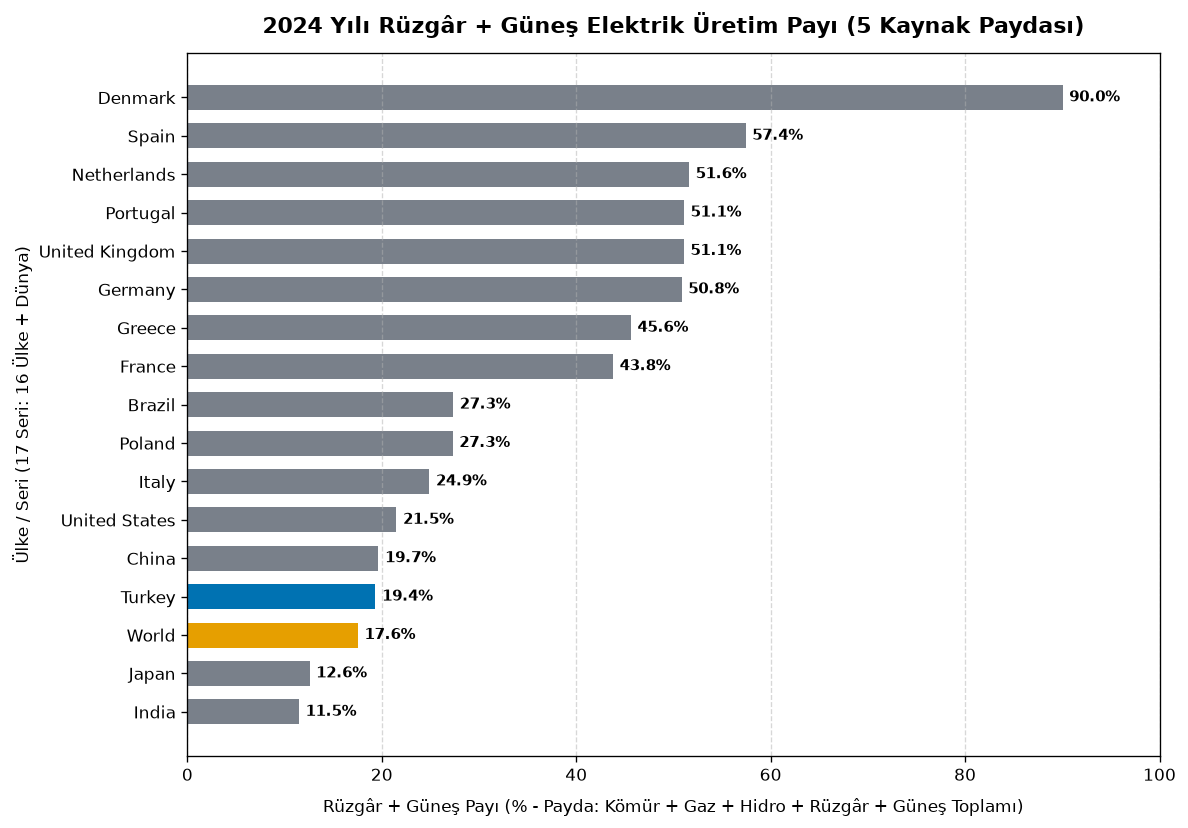

,Entity,WindSolar,FiveSourcesTotal,WindSolarShareFivePct
0,Denmark,24.19,26.87,90.03
1,Spain,120.49,209.82,57.43
2,Netherlands,55.30,107.15,51.61
3,Portugal,21.43,41.95,51.08
4,United Kingdom,98.07,192.03,51.07
5,Germany,215.73,424.30,50.84
6,Greece,23.81,52.19,45.62
7,France,70.30,160.54,43.79
8,Brazil,179.81,657.99,27.33
9,Poland,43.55,159.62,27.28


In [5]:
import matplotlib.pyplot as plt

comparison = processed[processed["Year"].eq(2024)].copy()
comparison["FiveSourcesTotal"] = comparison[five_sources].sum(axis=1, min_count=len(five_sources))
comparison["WindSolar"] = comparison[["Wind", "Solar"]].sum(axis=1, min_count=2)
comparison["WindSolarShareFivePct"] = 100 * comparison["WindSolar"] / comparison["FiveSourcesTotal"]

comp_sorted = comparison[["Entity", "WindSolar", "FiveSourcesTotal", "WindSolarShareFivePct"]].sort_values(
    "WindSolarShareFivePct", ascending=True, na_position="last"
).reset_index(drop=True)

# 2024 Ülke Karşılaştırma Grafiği (Seçilen tüm 16 ülke ve Dünya)
fig, ax = plt.subplots(figsize=(10, 7), dpi=120)

colors = []
for entity in comp_sorted["Entity"]:
    if entity == "Turkey":
        colors.append("#0072b2")  # Türkiye vurgusu (Mavi)
    elif entity == "World":
        colors.append("#e69f00")  # Dünya vurgusu (Kehribar)
    else:
        colors.append("#79808a")  # Diğer ülkeler (Nötr Gri)

bars = ax.barh(comp_sorted["Entity"], comp_sorted["WindSolarShareFivePct"], color=colors, height=0.65)

ax.set_title("2024 Yılı Rüzgâr + Güneş Elektrik Üretim Payı (5 Kaynak Paydası)", fontsize=13, pad=12, fontweight="bold")
ax.set_xlabel("Rüzgâr + Güneş Payı (% - Payda: Kömür + Gaz + Hidro + Rüzgâr + Güneş Toplamı)", fontsize=10, labelpad=8)
ax.set_ylabel("Ülke / Seri (17 Seri: 16 Ülke + Dünya)", fontsize=10)
ax.set_xlim(0, 100)
ax.grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:.1f}%",
                xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points",
                ha="left", va="center", fontsize=9, fontweight="semibold")

plt.tight_layout()
plt.show()

# Sıralı tablo gösterimi (Büyükten küçüğe)
comp_table = comp_sorted.sort_values("WindSolarShareFivePct", ascending=False).round(2).reset_index(drop=True)
comp_table

In [6]:
OUTPUT_PATHS = [
    PROJECT_ROOT / "data" / "islenmis_enerji_verisi.json",
    PROJECT_ROOT / "public" / "data" / "islenmis_enerji_verisi.json",
]

# Python/Pandas NaN değerlerini JSON standardına uygun null olarak yazar.
json_text = json.dumps(records, ensure_ascii=False, indent=2, allow_nan=False)
for output_path in OUTPUT_PATHS:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    output_path.write_text(json_text + "\n", encoding="utf-8")
    print(f"Kaydedildi: {output_path.relative_to(PROJECT_ROOT)}")

print(f"Toplam {len(records)} kayıt dışa aktarıldı; eksik değerler null olarak korundu.")

Kaydedildi: data\islenmis_enerji_verisi.json
Kaydedildi: public\data\islenmis_enerji_verisi.json
Toplam 1037 kayıt dışa aktarıldı; eksik değerler null olarak korundu.
